# Project Tittle:

 # 🛒 Blinkit Sales Analysis (2022–2023)


**Project Overview**
  
* This project presents a comprehensive analysis of Blinkit's grocery sales data to understand sales performance, customer purchasing behavior, 
and outlet performance. Using Python and data visualization libraries, the dataset is cleaned, explored, and analyzed to identify meaningful trends and
business insights. The analysis helps understand how different products, outlet types, and locations contribute to overall sales and supports 
data-driven business decision-making

**Research Questions**
* What is the total sales generated by Blinkit?
* Which product categories generate the highest revenue?
* Which outlet type contributes the most to total sales?
* How do sales vary across different outlet sizes and locations?
* Which item types are the most popular among customers? *Does item visibility affect product sales?
* How does item fat content influence sales performance?
* Which establishment years have the highest-performing outlets?


**Dataset Overview**
* Source: Blinkit Grocery Sales Dataset used for retail sales analysis and visualization.
* Coverage
* 🛒 Industry: Grocery Retail & E-commerce
* 📦 Products: Multiple grocery product categories
* 🏪 Outlets: Grocery Stores and Supermarkets
* 🌍 Outlet Locations: Tier 1, Tier 2, and Tier 3 Cities
* 📅 Establishment Years: 1985–2009
* 📊 Metrics: Item Sales, Item MRP, Item Visibility, Item Weight, Outlet Size, Outlet Type, Fat Content, and Product Categories

**Project Objective**
* Analyze Blinkit's overall sales performance.
* Understand customer purchasing behavior.
* Identify sales trends across products and outlets.
* Clean and preprocess the dataset.
* Visualize sales data using charts and dashboards.
* Compare outlet performance based on size and location.
* Analyze the impact of product attributes on sales.
* Generate business insights from the data.
* Provide recommendations for improving sales and profitability.
* Enhance data analysis and visualization skills using Python.


# Import Requried Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import plotly.graph_objects as go

# Display Library Versions

In [2]:
print("pandas version:",pd.__version__)
print("Numpy version:",np.__version__)
print("Matplotlib version:",matplotlib.__version__)
print("Seaborn Version:",sns.__version__)

pandas version: 3.0.3
Numpy version: 2.5.1
Matplotlib version: 3.11.0
Seaborn Version: 0.13.2


# Loading dataset

In [3]:
df=pd.read_csv("blinkit_orders.csv")
df

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741
...,...,...,...,...,...,...,...,...,...,...
4995,1669690997,62600289,2023-12-25 15:46:20,2023-12-25 16:05:20,2023-12-25 16:10:20,On Time,1132.33,Cash,90914,1587
4996,8340761903,53640286,2023-11-27 09:18:43,2023-11-27 09:38:43,2023-11-27 09:36:43,On Time,2372.01,Cash,27952,3458
4997,5936301790,87059497,2024-06-21 19:09:09,2024-06-21 19:23:09,2024-06-21 19:26:09,On Time,3158.35,Cash,9590,7424
4998,5710579377,67310893,2024-06-06 14:58:13,2024-06-06 15:12:13,2024-06-06 15:10:13,On Time,1918.92,UPI,29940,6128


# Data exploration

**Basic Dataset information**

In [4]:
df.shape

(5000, 10)

**Dataset information**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                5000 non-null   int64  
 1   customer_id             5000 non-null   int64  
 2   order_date              5000 non-null   str    
 3   promised_delivery_time  5000 non-null   str    
 4   actual_delivery_time    5000 non-null   str    
 5   delivery_status         5000 non-null   str    
 6   order_total             5000 non-null   float64
 7   payment_method          5000 non-null   str    
 8   delivery_partner_id     5000 non-null   int64  
 9   store_id                5000 non-null   int64  
dtypes: float64(1), int64(4), str(5)
memory usage: 739.9 KB


**Statatics Analysis**

In [6]:
df.describe()

,order_id,customer_id,order_total,delivery_partner_id,store_id
count,5.000000e+03,5.000000e+03,5000.00000,5000.000000,5000.000000
mean,5.029129e+09,5.009685e+07,2201.86170,50050.318200,4999.689000
std,2.863533e+09,2.919082e+07,1303.02438,28802.276922,2886.089242
min,6.046500e+04,3.181300e+04,13.25000,43.000000,1.000000
25%,2.531421e+09,2.404314e+07,1086.21500,24928.500000,2509.250000
50%,5.074378e+09,4.997808e+07,2100.69000,50262.500000,4987.000000
75%,7.488579e+09,7.621215e+07,3156.88250,74478.250000,7500.750000
max,9.998298e+09,9.989390e+07,6721.46000,99968.000000,9995.000000


* Unique values per column

In [7]:
for col in df.columns:
    display(pd.DataFrame({col: df[col].unique()}))

,order_id
0,1961864118
1,1549769649
2,9185164487
3,9644738826
4,5427684290
...,...
4995,1669690997
4996,8340761903
4997,5936301790
4998,5710579377


,customer_id
0,30065862
1,9573071
2,45477575
3,88067569
4,83298567
...,...
2167,10745302
2168,71767248
2169,16484167
2170,86483673


,order_date
0,2024-07-17 08:34:01
1,2024-05-28 13:14:29
2,2024-09-23 13:07:12
3,2023-11-24 16:16:56
4,2023-11-20 05:00:39
...,...
4995,2023-12-25 15:46:20
4996,2023-11-27 09:18:43
4997,2024-06-21 19:09:09
4998,2024-06-06 14:58:13


,promised_delivery_time
0,2024-07-17 08:52:01
1,2024-05-28 13:25:29
2,2024-09-23 13:25:12
3,2023-11-24 16:34:56
4,2023-11-20 05:17:39
...,...
4994,2023-12-25 16:05:20
4995,2023-11-27 09:38:43
4996,2024-06-21 19:23:09
4997,2024-06-06 15:12:13


,actual_delivery_time
0,2024-07-17 08:47:01
1,2024-05-28 13:27:29
2,2024-09-23 13:29:12
3,2023-11-24 16:33:56
4,2023-11-20 05:18:39
...,...
4995,2023-12-25 16:10:20
4996,2023-11-27 09:36:43
4997,2024-06-21 19:26:09
4998,2024-06-06 15:10:13


,delivery_status
0,On Time
1,Slightly Delayed
2,Significantly Delayed


,order_total
0,3197.07
1,976.55
2,839.05
3,440.23
4,2526.68
...,...
4545,1132.33
4546,2372.01
4547,3158.35
4548,1918.92


,payment_method
0,Cash
1,UPI
2,Card
3,Wallet


,delivery_partner_id
0,63230
1,14983
2,39859
3,61497
4,84315
...,...
4995,90914
4996,27952
4997,9590
4998,29940


,store_id
0,4771
1,7534
2,9886
3,7917
4,2741
...,...
4995,1587
4996,3458
4997,7424
4998,6128


* Memory usage

In [8]:
df.memory_usage()

Index                        132
order_id                   40000
customer_id                40000
order_date                135000
promised_delivery_time    135000
actual_delivery_time      135000
delivery_status            91235
order_total                40000
payment_method             61274
delivery_partner_id        40000
store_id                   40000
dtype: int64

**Display the first five rows**

In [9]:
df.head()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741


**Display the last five rows**

In [10]:
df.tail()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
4995,1669690997,62600289,2023-12-25 15:46:20,2023-12-25 16:05:20,2023-12-25 16:10:20,On Time,1132.33,Cash,90914,1587
4996,8340761903,53640286,2023-11-27 09:18:43,2023-11-27 09:38:43,2023-11-27 09:36:43,On Time,2372.01,Cash,27952,3458
4997,5936301790,87059497,2024-06-21 19:09:09,2024-06-21 19:23:09,2024-06-21 19:26:09,On Time,3158.35,Cash,9590,7424
4998,5710579377,67310893,2024-06-06 14:58:13,2024-06-06 15:12:13,2024-06-06 15:10:13,On Time,1918.92,UPI,29940,6128
4999,2494813730,28663279,2023-08-23 12:04:18,2023-08-23 12:20:18,2023-08-23 12:21:18,On Time,1879.46,Card,32851,5588


# Data preprocessing

**Finding Missing Values**

In [11]:
df.isnull().sum()

order_id                  0
customer_id               0
order_date                0
promised_delivery_time    0
actual_delivery_time      0
delivery_status           0
order_total               0
payment_method            0
delivery_partner_id       0
store_id                  0
dtype: int64

**Duplicated valus**

In [12]:
df.duplicated().sum()

np.int64(0)

**Creating new feature**

### 1. Data Type of the order_date before type conversion

In [13]:
print(df["order_date"].dtype)

str


In [14]:
df["order_date"]=pd.to_datetime(df["order_date"])
df["actual_delivery_time"]=pd.to_datetime(df["actual_delivery_time"])

### Data Type of the `order_date` column after type conversion

In [15]:
print(df["order_date"].dtype)

datetime64[us]


### 2. Data type of the `promised_delivery_time` column before conversion

In [16]:
print(df["promised_delivery_time"].dtype)

str


In [17]:
df["promised_delivery_time"]=pd.to_datetime(df["promised_delivery_time"])

### Data type of the `promised_delivery_time` column after conversion

In [18]:
print(df["promised_delivery_time"].dtype)

datetime64[us]


In [19]:
df["year"]=df["order_date"].dt.year
df["month name"]=df["order_date"].dt.month_name()
df["day"]=df["order_date"].dt.day
df["date_only"]=df["order_date"].dt.date
df["hour"]=df["order_date"].dt.hour
df["minutee"]=df["order_date"].dt.minute
df["weekday"]=df["order_date"].dt.weekday
df["quantity"]=1
df["item_price"]=df["order_total"]
df["item_outlet_sales"]=df["item_price"]*df["quantity"]               
np.random.seed(42)
df["item_visibiltiy"]=np.random.uniform(0,0.2,size=len(df))
categories=["food","drink","household","electronic","clothing"]
np.random.seed(42)
df["item_type"]=np.random.choice(categories,size=len(df))
outlet_types=["grocerystore","supermarket type1","supermarket type2","supermarket type3"]
np.random.seed(42)
df["outlet_type"]=np.random.choice(outlet_types,size=len(df))
np.random.seed(42)
df["rating"]=np.round(np.random.uniform(1,5,size=len(df)),1)
location_types=["tier1","tier2","tire3"]
np.random.seed(42)
df["outlet_location_type"]=np.random.choice(location_types,size=len(df))
fat_types=["Low Fat","Regular"]
np.random.seed(42)
df["item_fat_content"]=np.random.choice(fat_types,size=len(df))
df["sales"]=df["item_price"]*df["quantity"]
np.random.seed(42)
df["outlet establishment year"]=np.random.randint(1999,2016,size=len(df))
df.head()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id,...,item_price,item_outlet_sales,item_visibiltiy,item_type,outlet_type,rating,outlet_location_type,item_fat_content,sales,outlet establishment year
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771,...,3197.07,3197.07,0.074908,electronic,supermarket type2,2.5,tire3,Low Fat,3197.07,2005
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534,...,976.55,976.55,0.190143,clothing,supermarket type3,4.8,tier1,Regular,976.55,2013
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886,...,839.05,839.05,0.146399,household,grocerystore,3.9,tire3,Low Fat,839.05,2009
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917,...,440.23,440.23,0.119732,clothing,supermarket type2,3.4,tire3,Low Fat,440.23,2006
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741,...,2526.68,2526.68,0.031204,clothing,supermarket type2,1.6,tier1,Low Fat,2526.68,2005


# EDA Analysis

**Hourly Orders Trends Analysis**

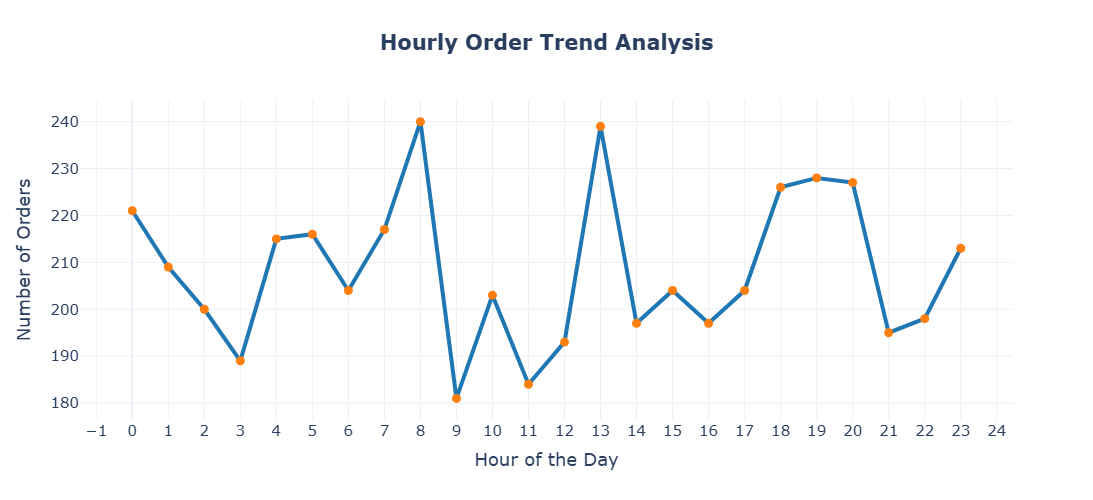

In [20]:
import plotly.express as px

# Group data by hour
hourly_orders = (
    df.groupby("hour")["order_id"]
      .count()
      .reset_index(name="Orders")
)

# Create Interactive Line Chart
fig = px.line(
    hourly_orders,
    x="hour",
    y="Orders",
    markers=True,
    title="<b>Hourly Order Trend Analysis</b>",
    labels={
        "hour": "Hour of the Day",
        "Orders": "Number of Orders"
    },
    template="plotly_white"
)

# Customize the chart
fig.update_traces(
    line=dict(color="#1f77b4", width=4),
    marker=dict(size=9, color="#ff7f0e")
)

fig.update_layout(
    title_x=0.5,
    font=dict(size=15),
    xaxis=dict(
        tickmode='linear',
        dtick=1,
        showgrid=True
    ),
    yaxis=dict(showgrid=True),
    hovermode="x unified",
    width=900,
    height=500
)

fig.show()

**Graph Explanation**
* The line chart shows how the number of orders changes throughout the day.
* Order volume reaches its highest level around 8 AM and 1 PM, indicating peak customer activity.
* A noticeable drop in orders occurs around 9 AM, representing a low-demand period.
* These insights help Blinkit optimize staffing, inventory management, and delivery operations during peak and off-peak hours.

**Monthly Orders Analysis**

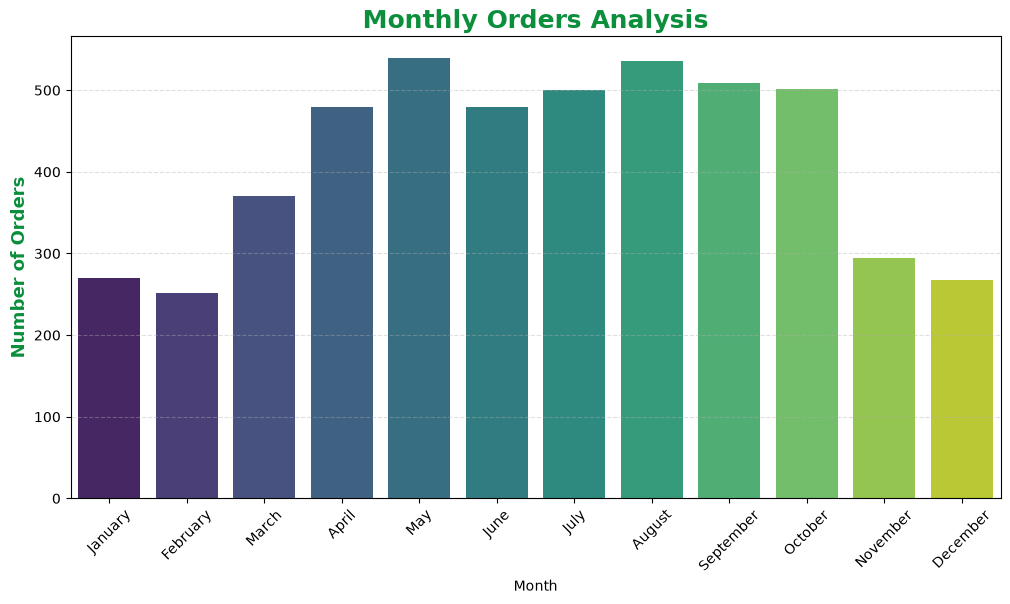

In [21]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]
monthly_orders = (
    df.groupby("month name")["order_id"]
      .count()
      .reindex(month_order)
      .reset_index(name="Orders")
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=monthly_orders,
    x="month name",
    y="Orders",
   hue="month name", palette="viridis"
)

plt.title("Monthly Orders Analysis", fontsize=18, fontweight="bold",color="#0B8F3C")
plt.xlabel("Month")
plt.ylabel("Number of Orders",fontsize=13, fontweight="bold", color="#0B8F3C")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

**Graph Explanation**
* The chart shows the total number of orders placed in each month.
* Orders increase during the middle months and decrease in some later months.
* This analysis helps identify seasonal demand patterns for better inventory and staffing planning.

**Payment Method Distribution**

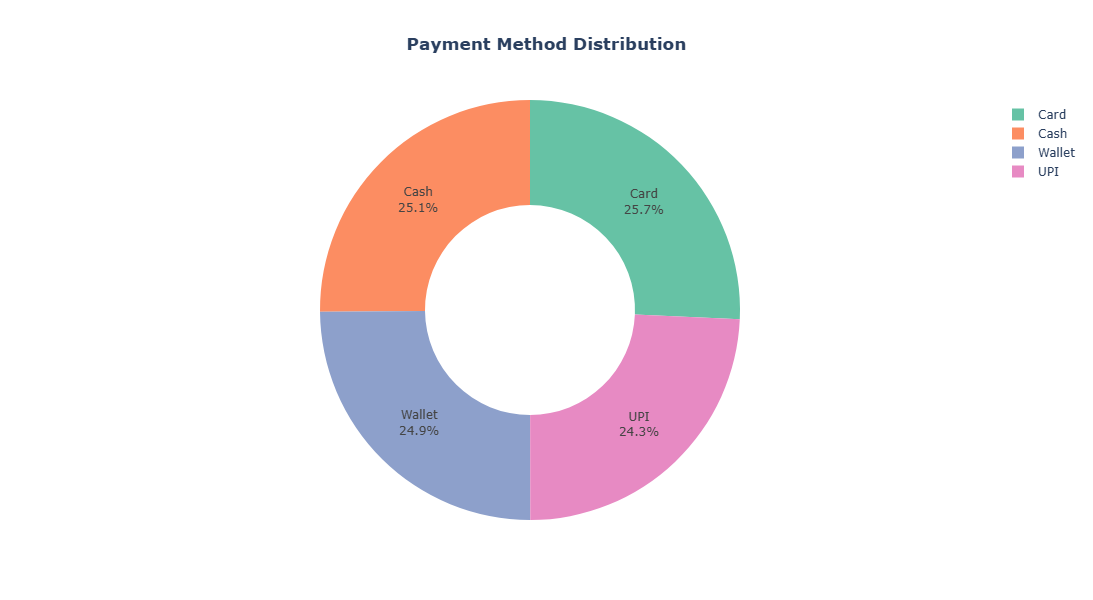

In [22]:


payment = (
    df["payment_method"]
    .value_counts()
    .reset_index()
)

payment.columns = ["Payment Method", "Orders"]

fig = px.pie(
    payment,
    names="Payment Method",
    values="Orders",
    hole=0.5,
    color="Payment Method",
    color_discrete_sequence=px.colors.qualitative.Set2,
    title="<b>Payment Method Distribution</b>"
)

fig.update_traces(
    textinfo="percent+label",
    textposition="inside"
)

fig.update_layout(
    title_x=0.5,
    width=700,
    height=600
)

fig.show()

**Graph Explanation**
* The donut chart displays the percentage share of each payment method.
* It clearly shows which payment method is most popular among customers.
* Businesses can use this information to optimize payment options and encourage the use of preferred payment methods

**Delivery Status Distribution**

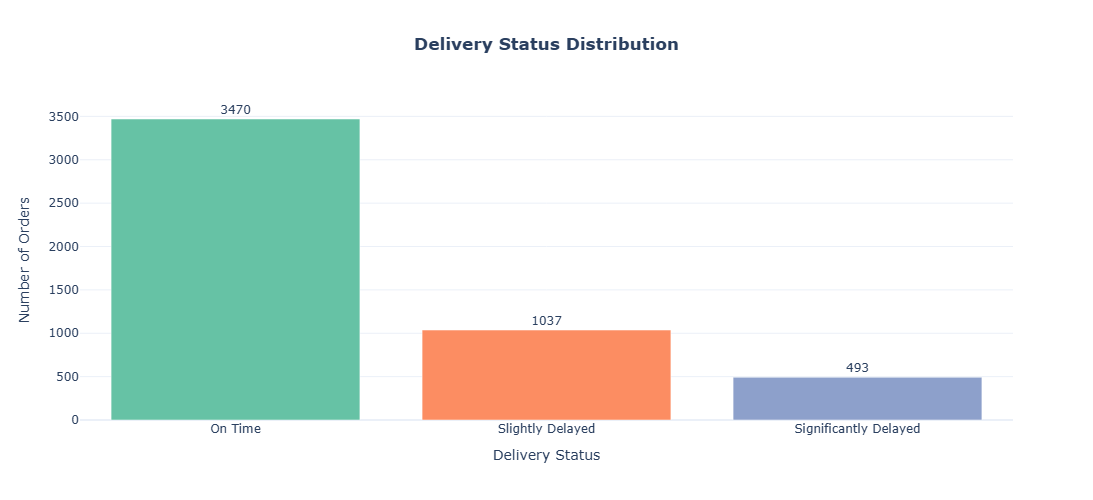

In [23]:
import plotly.express as px

delivery_status = (
    df["delivery_status"]
    .value_counts()
    .reset_index()
)

delivery_status.columns = ["Delivery Status", "Orders"]

fig = px.bar(
    delivery_status,
    x="Delivery Status",
    y="Orders",
    text="Orders",
    color="Delivery Status",
    color_discrete_sequence=px.colors.qualitative.Set2,
    title="<b>Delivery Status Distribution</b>",
    template="plotly_white"
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Delivery Status",
    yaxis_title="Number of Orders",
    width=800,
    height=500,
    showlegend=False
)

fig.show()

**Graph Explanation**
* The chart shows the number of orders for each delivery status.
* The status with the tallest bar represents the most common delivery outcome.
* This analysis helps monitor delivery performance and identify areas that may require operational improvements.

**Order Amount Distribution**

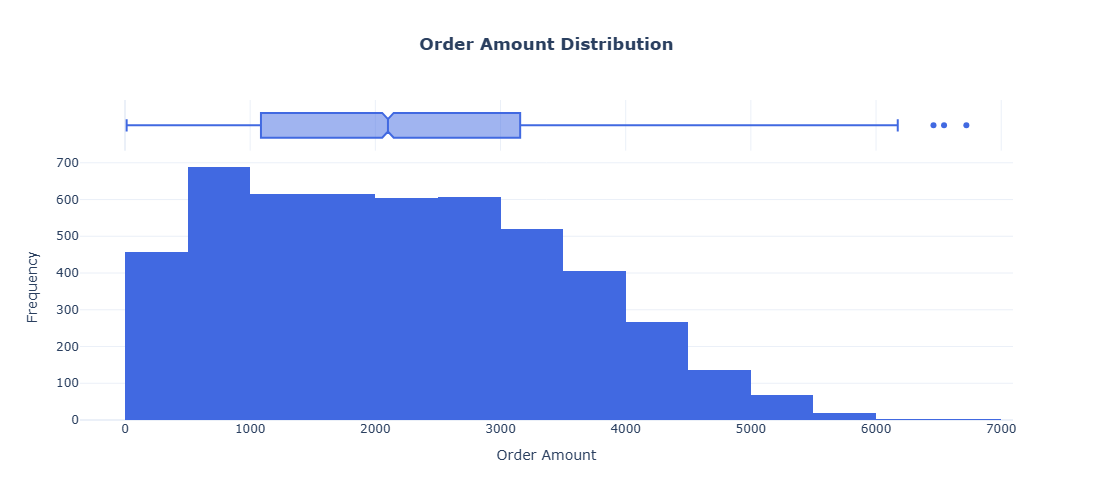

In [24]:


fig = px.histogram(
    df,
    x="order_total",
    nbins=25,
    marginal="box",
    color_discrete_sequence=["royalblue"],
    title="<b>Order Amount Distribution</b>",
    template="plotly_white"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Order Amount",
    yaxis_title="Frequency",
    width=900,
    height=500
)

fig.show()

**Graph Explanation**
* The interactive histogram displays how order amounts are distributed.
* The box plot above the histogram highlights the spread of the data and any potential outliers.
* It helps understand customer spending behavior and identify the most common order value ranges.

**Average Sales and Item Visibility Across Products**

In [25]:


avg_sales = df["item_outlet_sales"].mean()
avg_visibility = df["item_visibiltiy"].mean()

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Average Sales", "Average Item Visibility")
)

fig.add_trace(
    go.Bar(
        x=["Average Sales"],
        y=[avg_sales],
        text=[round(avg_sales,2)],
        textposition="outside",
        name="Sales"
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Bar(
        x=["Average Visibility"],
        y=[avg_visibility],
        text=[round(avg_visibility,3)],
        textposition="outside",
        name="Visibility"
    ),
    row=1,
    col=2
)

fig.update_layout(
    title="Average Sales and Item Visibility Across Products",
    showlegend=False,
    height=500,
    width=900
)

fig.show()

NameError: name 'make_subplots' is not defined

**Graph Explanation**
* The graph shows the average sales and average item visibility of products.
* The average sales are approximately ₹2201.86 per product.
* The average item visibility is around 0.10, indicating the average visibility score of products.
* Separate charts are used because sales and visibility have different scales and units.
* This visualization provides a clear overview of the average performance of products in the Blinkit dataset.

**Sales by Product Category and Outlet Type**

In [ ]:
pivot = (
    df.groupby(["item_type", "outlet_type"])["item_outlet_sales"]
      .sum()
      .reset_index()
)

fig = px.bar(
    pivot,
    x="item_type",
    y="item_outlet_sales",
    color="outlet_type",
    barmode="group",
    title="Sales by Product Category and Outlet Type"
)

fig.update_layout(xaxis_tickangle=-45)

fig.show()

***Explanation***
* The graph compares the total sales of each product category across different outlet types.
* Each color represents a different outlet type (Grocery Store, Supermarket Type1, Type2, and Type3).
* Food and Clothing categories generate the highest sales in most outlet types.
* Drink and Household categories show comparatively lower sales in some outlet types.
* The graph helps identify which outlet type performs best for each product category.
* It can be used to optimize inventory planning, product placement, and marketing strategies for different outlet types.
* Blinkit can focus on stocking high-demand product categories in the outlet types where they perform best to increase overall sales.

**Average Sales, Rating and Item Visibility**

In [ ]:


summary = pd.DataFrame({
    "Metric": ["Average Sales", "Average Rating", "Average Visibility"],
    "Value": [
        df["item_outlet_sales"].mean(),
        df["rating"].mean(),
        df["item_visibiltiy"].mean()
    ]
})

fig = px.scatter(
    summary,
    x="Metric",
    y="Value",
    size="Value",
    color="Metric",
    text="Value",
    size_max=80,
    title="Average Sales, Rating and Item Visibility"
)

fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="top center"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis_title="Metrics",
    yaxis_title="Average Value",
    font=dict(size=14)
)

fig.show()

**Graph Explanation**
* Displays the average sales, average rating, and average item visibility of Blinkit products.
* Average Sales are much higher than the other two metrics because they are measured in currency.
* Average Rating indicates the overall customer satisfaction level.
* Average Visibility represents the average shelf/display visibility of products.
* The visualization provides a quick overview of the key performance metrics and helps evaluate overall product performance.

**Research Question 1.What is the total sales generated by Blinkit?**

In [ ]:
import plotly.graph_objects as go

total_sales = df["item_outlet_sales"].sum()

fig = go.Figure(go.Indicator(
    mode="number",
    value=total_sales,
    number={"prefix":"₹","valueformat":",.2f"},
    title={"text":"Total Sales Generated by Blinkit"}
))

fig.update_layout(height=350)

fig.show()

**Research Question 2.Which product categories generate the highest revenue?**

In [ ]:
import plotly.express as px

# Total revenue by product category
category_sales = (
    df.groupby("item_type")["item_outlet_sales"]
      .sum()
      .reset_index()
      .sort_values(by="item_outlet_sales", ascending=True)
)

fig = px.bar(
    category_sales,
    x="item_outlet_sales",
    y="item_type",
    orientation="h",
    color_continuous_scale="Viridis",
    text="item_outlet_sales",
    title="Revenue Generated by Product Categories"
)

fig.update_traces(texttemplate='₹%{text:,.0f}', textposition='outside')

fig.update_layout(
    xaxis_title="Total Revenue (₹)",
    yaxis_title="Product Category",
    title_x=0.5,
    template="plotly_white"
)

fig.show()

**Analysis**
* The chart compares the total revenue generated by each product category in the Blinkit dataset
* Categories with longer bars contribute more to Blinkit's overall sales

**Key Insights***
* Top-performing categories generate the highest share of total revenue.
* Lower-performing categories contribute comparatively less and may need promotional efforts.
* The graph helps identify customer purchasing preferences based on sales.
* Blinkit can increase inventory for high-demand categories to avoid stock shortages.
* Marketing campaigns and discounts can be targeted toward lower-performing categories to improve their sales.


**Research Question 3.Which outlet type contributes the most to total sales?**

In [ ]:
import plotly.express as px

outlet_sales = (
    df.groupby("outlet_type")["item_outlet_sales"]
      .sum()
      .reset_index()
)

fig = px.pie(
    outlet_sales,
    names="outlet_type",
    values="item_outlet_sales",
    hole=0.45,
    color_discrete_sequence=px.colors.qualitative.Set2,
    title="Total Sales by Outlet Type"
)

fig.update_traces(textinfo="percent+label")

fig.show()

**Analysis**
* The chart compares the total sales generated by each outlet type.
* It identifies the outlet type with the highest contribution to overall revenue.
* Outlet types with higher sales indicate stronger customer demand and better performance.


**Key Insights**
* {highest_outlet} generates the highest total sales.
* It contributes the largest share of Blinkit's overall revenue.
* Lower-performing outlet types may require better inventory planning and marketing.
* Blinkit can prioritize investment in high-performing outlet types to increase revenue.

**Research Question 4.How do sales vary across different outlet sizes and locations?**

In [ ]:
location_sales = (
    df.groupby("outlet_location_type")["item_outlet_sales"]
      .sum()
      .reset_index()
)

fig = px.bar(
    location_sales,
    x="outlet_location_type",
    y="item_outlet_sales",
    color="outlet_location_type",
    text_auto=".2s",
    title="Total Sales by Outlet Location",
    color_discrete_sequence=px.colors.qualitative.Bold
)

fig.update_layout(
    xaxis_title="Outlet Location",
    yaxis_title="Total Sales",
    title_x=0.5,
    template="plotly_white"
)

fig.show()

**Analysis**
* The graph compares the total sales generated across different outlet locations.
* It helps identify which location tier contributes the most to Blinkit's overall revenue.
* Higher sales in a location indicate strong customer demand and better outlet performance

**Key Insights**
* Tier 3 outlets generate the highest total sales, indicating strong customer demand in these locations.
* Tier 2 outlets show moderate sales performance.
* Tier 1 outlets contribute the lowest total sales among the three location types.


**Research Question 5. Which item types are the most popular among customers?Does item visibility affect product sales?**

In [ ]:
item_count = (
    df["item_type"]
    .value_counts()
    .reset_index()
)

item_count.columns = ["item_type", "Count"]

fig = px.bar(
    item_count,
    x="item_type",
    y="Count",
    color="Count",
    title="Most Popular Item Types",
    text="Count"
)

fig.update_layout(
    xaxis_title="item Type",
    yaxis_title="Number of Products",
    xaxis_tickangle=-45,
    template="plotly_white"
)

fig.show()

**Analysis**
* The bar chart compares the number of products sold across five item categories: Clothing, Food, Electronic, Household, and Drink. The sales 
counts are very close, indicating that customer demand is fairly balanced across all categories.

**Key Insights**
* 👕 Clothing is the most popular item category with 1,024 sales, making it the highest-selling category.
* 🍔 Food ranks second with 1,019 sales, showing consistently high customer demand.
* 💻 Electronic products are a close third with 1,009 sales, indicating strong market interest.
* 🏠 Household items recorded 983 sales, performing slightly below the top three categories.
* 🥤 Drink products have the lowest sales (965), making them the least popular category in this dataset.

**Research Question 6.How does item fat content influence sales performance?**

In [ ]:

fat_sales = (
    df.groupby('item_fat_content', as_index=False)['sales']
      .sum()
)

fig = px.bar(
    fat_sales,
    x='item_fat_content',
    y='sales',
    color='item_fat_content',
    text='sales',
    title='sales by item fat content'
)

fig.update_traces(
    texttemplate='%{text:.2s}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='item fat content',
    yaxis_title='total sales',
    showlegend=False
)

fig.show()

**Analysis**
* The chart compares total sales between Low Fat and Regular fat content products.
* Low Fat products generated approximately ₹5.6M in total sales.
* Regular products generated approximately ₹5.4M in total sales.
* The sales difference between the two categories is relatively small, indicating that both product types are popular among customers.

**Key Insights**
* Low Fat products are the top-selling category, contributing around ₹5.6M in sales.
* Regular fat products also perform strongly, with total sales of approximately ₹5.4M.
* The sales gap between the two categories is only about ₹0.2M (₹200K), showing nearly equal customer demand.
* Customers exhibit a slight preference for Low Fat products, possibly due to increasing health awareness.

**Reasearch Question 7.Which establishment years have the highest-performing outlets?**

In [ ]:
import plotly.express as px

# total sales by establishment year
year_sales = (
    df.groupby('outlet establishment year', as_index=False)['sales']
      .sum()
      .sort_values('outlet establishment year')
)

# bar chart
fig = px.bar(
    year_sales,
    x='outlet establishment year',
    y='sales',
    color='sales',
    text='sales',
    title='total sales by outlet establishment year',
    color_continuous_scale='blues'
)

fig.update_traces(
    texttemplate='%{text:.2s}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='establishment year',
    yaxis_title='total sales'
)

fig.show()

**Analysis**
* The chart shows the total sales generated by outlets based on their establishment year.
* Outlet performance varies across different establishment years, with sales ranging from approximately ₹580K to ₹740K.
* The highest sales were recorded by outlets established in 2015, generating around ₹740K.
* Outlets established in 2006 and 2013 are the second-highest performers, each contributing approximately ₹710K.
* The lowest sales were observed for outlets established in 2008 and 2014, with approximately ₹580K each

**Key Insights**
* 2015 outlets are the best-performing, with total sales of approximately ₹740K.
* 2006 and 2013 outlets also perform exceptionally well, each generating around ₹710K in sales.
* 2001 and 2011 show strong performance with sales close to ₹670K–₹690K.
* Outlets established in 2008 and 2014 have the lowest sales, indicating potential areas for operational improvements or targeted marketing.
* Most establishment years generate sales between ₹600K and ₹700K, indicating relatively stable performance across outlet generations.
*The findings suggest that newer outlets (2015) can perform as well as or better than older outlets, showing successful expansion and effective
outlet management.

**Conclusion**
* This Blinkit Sales Analysis project provides valuable insights into product performance, outlet efficiency, and customer purchasing behavior. The 
analysis reveals that outlet type, establishment year, and product category have a greater impact on sales than product visibility alone. Medium-sized
outlets and Tier 3 locations demonstrate strong business performance, while Supermarket Type 1 contributes the highest revenue. These findings can
help Blinkit optimize inventory management, improve outlet planning, and focus marketing efforts on high-performing products and locations. Overall,
the project demonstrates how data analytics can support informed business decisions and drive sales growth.